05/10/23

**For part 1: phase per channel**

1. plot uncorrected results on topomap per subject
   - create a new script.
   - adjust script to include new colormap
     - where are the original scripts?
   - load each of the uncorrected results
   - calculate the max and min values across all subjects
   - set the vmin and vmax values
   - save files.
   - make contact sheet.
2. run through fdr for all subjects
   - collect all subjects p-values + list of channels
     - as well as length of channel list.
     - subject: [n? channel x timepoint]
   - function to combine and separate the matrices.

In [73]:
#load packages, set plotting parameters
import os, sys
import numpy as np
import itertools, warnings

sys.path.append("/project_data/volume0/tpirnia/data/EEGWS/code")
from data_handling.preprocessing import get_bad_channels
from statsmodels.stats.multitest import multipletests                                          
import matplotlib.pyplot as plt
import mne

from mpl_toolkits import axes_grid1
from matplotlib import colors
import matplotlib as mpl
import seaborn as sns

params = {
    "lines.markersize": 6,
    "axes.labelsize": 30,
    "axes.titlesize": 40,
    "axes.labelpad": 8,
    "xtick.labelsize": 18,
    "ytick.labelsize": 22,
    "xtick.major.pad": 5,
    "ytick.major.pad": 5,
    "legend.title_fontsize": 18,
    "figure.figsize": (8, 10),
    "figure.subplot.hspace": 0.9,
    "figure.subplot.wspace": 0.4,
    "image.origin": "lower",
    "figure.titlesize": 30,
    "figure.autolayout": False,
    "scatter.marker": "o",
    "savefig.dpi": 450,
    "savefig.bbox": "tight",
    "savefig.transparent": True,
}


# need to fix range numbers!!!

In [147]:
# define functions
def fill_path(fname):
    if not os.path.exists(os.path.dirname(fname)):
        os.makedirs(os.path.dirname(fname), exist_ok=True)


def nulldist(nulls, yhat):
    """CALCULATE P-VALUE"""
    pv0 = sum(nulls >= yhat) + 1
    return pv0 / (len(nulls) + 1)


def channel_indices(n_channels, bad_channels):
    channels = np.arange(n_channels)
    good_ch = channels[np.isin(channels, bad_channels, invert=True)]
    # mask_ch = np.argwhere(good_ch).squeeze()
    bad_names = list("E" + str(bc + 1) for bc in bad_channels)
    return good_ch, bad_channels, bad_names

def mask_arr_by_ind(arr, inds, mask_value):
    arr_tmp = arr.copy()
    arr_tmp[inds] = mask_value
    return arr_tmp

def add_bad_ch_in(n_channels, good_ch, arr):
    """for full trial only, needs a second dimension for time otherwise."""
    tmp_ = np.zeros(shape=(n_channels,))
    tmp_[good_ch] = arr.copy()
    return tmp_


In [ ]:
def plot_acc_brain(
    arr,
    info,
    subject,
    params,
    ch_badmask=None,
    title="",
    fname="",
    show=True,
    all_subjects=False,
    vmax=100,
    vmin=50,
    include_cbar=True,
):
    if arr.ndim > 1:
        arr = arr.squeeze()
    mask_params = dict(
        marker="o", markerfacecolor="w", markeredgecolor="k", linewidth=0, markersize=15
    )
    with mpl.rc_context(params):
        # plt.style.use('seaborn-darkgrid')
        plt.style.use("seaborn-v0_8-poster")
        figsize, cbar_labelsize, cbar_ticksize, rangetext_size = (8,8), 30, 25, 25
        fig, ax = plt.subplots(figsize=figsize)
        if any(ch_badmask):
            im, cm = mne.viz.plot_topomap(
                arr * 100,
                pos=info,
                axes=ax,
                show=False,
                #show_names=True,
                names=info.ch_names,
                mask=ch_badmask,
                cmap="YlOrRd",
                mask_params=mask_params,
                vlim=(50,100),
                res=300,
                ch_type="eeg")
        else:
            im, cm = mne.viz.plot_topomap(
                arr * 100,
                pos=info,
                axes=ax,
                #show_names=False,
                #names=info.ch_names,
                show=False,
                vlim=(50,100),
                res=300,
                ch_type="eeg",
                cmap="YlOrRd")  
            textstr = r"accuracy range$:%.1f-%.1f$%%" % (min(arr) * 100, max(arr) * 100)
        textstr = r"accuracy range$:%.1f-%.1f$%%" % (vmin* 100, vmax * 100)
        if all_subjects:
            fig.suptitle("{} {}".format(subject, title))

        else:
            fig.suptitle(" Participant {} {}".format(int(subject[-2:]), title),y=.99)
        ax_x_start = 1.0
        ax_x_width = 0.04
        ax_y_start = 0.15
        ax_y_height = 0.75
        cbar_ax = fig.add_axes([ax_x_start, ax_y_start, ax_x_width, ax_y_height])
        clb = fig.colorbar(im, cax=cbar_ax, label="Accuracy (%)",)
        clb.mappable.set_clim(50,100) # type: ignore
        clb.set_ticks([ 50.,  60.,  70.,    80.,    90.,   100.])
        
        ##cbar_ax._axis_map.values()[1].set_label_text("accuracy (%)", size=20) #deprecated method
        ##cbar_ax.axes.get_a _get_axis_list()[1].set_label_position("left") #deprecated method
        
        clb.ax.tick_params(labelsize=cbar_ticksize)
        clb.ax.set_ylabel(clb.ax.get_ylabel(), size=cbar_labelsize)
        props = dict(boxstyle="round", facecolor="wheat", alpha=0.25, pad=0.15)
        cbar_ax.set_visible(include_cbar)
        # place a text box in upper left in axes coords
        ax.text(
            0.01,
            -0.04,
            textstr,
            transform=ax.transAxes,
            fontsize=rangetext_size,
            verticalalignment="top",
            bbox=props,
        )
        
        if fname:
            plt.savefig(fname, dpi=450, transparent=True, bbox_inches="tight")
        if show:
            plt.show()
        else:
            plt.close()
        return fig, cbar_ax, clb


In [22]:
#mne topoplot montage
sfreq = float(1000)
decim = 2

montage = mne.channels.make_standard_montage("GSN-HydroCel-129")
info = mne.create_info(montage.ch_names, sfreq=sfreq, ch_types="eeg",verbose=0)
info.set_montage(montage, verbose=0)

<Info | 8 non-empty values
 bads: []
 ch_names: E1, E2, E3, E4, E5, E6, E7, E8, E9, E10, E11, E12, E13, E14, ...
 chs: 129 EEG
 custom_ref_applied: False
 dig: 132 items (3 Cardinal, 129 EEG)
 highpass: 0.0 Hz
 lowpass: 500.0 Hz
 meas_date: unspecified
 nchan: 129
 projs: []
 sfreq: 1000.0 Hz
>

In [125]:
# set variables and file names
subject_list = "EP03 EP05 EP06 EP07 EP09 EP10 EP11 EP12 EP13 EP14 EP15 EP16 EP17 EP18 EP19 EP20 EP21 EP22 EP23 EP25 EP26 EP27 EP28 EP29 EP30 EP31 EP32 EP33".split(
    " ")

w, s = 1000, 500

project_path = "/project_data/volume0/tpirnia/data/EEGWS/"
data_path = "{}results_alias/ch1-by_channel/data/w{}".format(project_path, w)

min_acc, max_acc = [], []
RESULTS_ = {}

PVALUES = np.empty((0, 1))
subj_inds = np.empty((0, 1), dtype=int)

In [132]:
#make uncorrected figures for all participants (50-100% accuracy) with colorbar
for si, subject in enumerate(subject_list):    #subject = sys.argv[1]

    # Files to save:
    fig_fname = (
        project_path
        + "/results_alias/ch1-by_channel/figures/w1000/{}_by_channel".format(subject)
    )

    obs_fname ='{}/{}_by_channel_test.npy'.format(data_path, subject)
    obs_ = np.load(obs_fname)
    obs_m = obs_.mean(axis=1).squeeze()

    #number of channels
    test_d1 = obs_.shape[0]
    bad_d1 = get_bad_channels(project_path,subject) #bad channels
    good_d1, bad_d1, bad_names = channel_indices(test_d1, bad_d1)

    try:
        min_acc.append(np.min(obs_m[good_d1]))
        max_acc.append(np.max(obs_m[good_d1]))
    except:
        print("Continued without appending to min_acc and max_acc--they aren't lists.")
    
    pval_fname = '{}/sig/{}_by_channel-pval.npy'.format(data_path, subject)
    pvalues = np.load(pval_fname)

    tmp = np.empty(shape=pvalues[good_d1].shape,dtype=int)
    tmp[:]=si
    PVALUES = np.concatenate([PVALUES,pvalues[good_d1]])
    subj_inds = np.concatenate((subj_inds,tmp))

    RESULTS_[subject] = {   'obs': obs_,
                            'obs_m': obs_m,
                            'min_acc': np.min(obs_m[good_d1]),
                            'max_acc': np.max(obs_m[good_d1]),
                            'pvalues': pvalues,
                            'd1': test_d1,
                            'good_d1': good_d1,
                            'bad_d1': bad_d1,
                            'bad_names': bad_names,
                            'fig_fname': fig_fname,
                            }
    
    info['bads'] = bad_names
    ch_badmask = np.isin(info.ch_names,info['bads'],invert=False)

    #res_tmp[RESULTS_[subject]['obs_m']<0.55] = 0
    fig, cbar_ax, colbr = plot_acc_brain(
        obs_m,
        info,
        subject=subject,
        params=params,
        ch_badmask=ch_badmask,
        title="",
        show=False,
        all_subjects=False,
        vmin=RESULTS_[subject]['min_acc'],
        vmax=RESULTS_[subject]['max_acc'],
        fname=(RESULTS_[subject]['fig_fname'] + "_YlOrRd.png"))

min_acc, max_acc = map(np.array,[min_acc,max_acc])

In [144]:
#make uncorrected figures for all participants (50-100% accuracy) without colobrbar
for si, subject in enumerate(subject_list):    #subject = sys.argv[1]

    # Files to save:
    fig_fname = (
        project_path
        + "/results_alias/ch1-by_channel/figures/w1000/{}_by_channel".format(subject)
    )

    obs_fname ='{}/{}_by_channel_test.npy'.format(data_path, subject)
    obs_ = np.load(obs_fname)
    obs_m = obs_.mean(axis=1).squeeze()

    #number of channels
    test_d1 = obs_.shape[0]
    bad_d1 = get_bad_channels(project_path,subject) #bad channels
    good_d1, bad_d1, bad_names = channel_indices(test_d1, bad_d1)

    try:
        min_acc.append(np.min(obs_m[good_d1]))
        max_acc.append(np.max(obs_m[good_d1]))
    except:
        print("Continued without appending to min_acc and max_acc--they aren't lists.")
        
    pval_fname = '{}/sig/{}_by_channel-pval.npy'.format(data_path, subject)
    pvalues = np.load(pval_fname)

    tmp = np.empty(shape=pvalues[good_d1].shape,dtype=int)
    tmp[:]=si
    PVALUES = np.concatenate([PVALUES,pvalues[good_d1]])
    subj_inds = np.concatenate((subj_inds,tmp))

    RESULTS_[subject] = {   'obs': obs_,
                            'obs_m': obs_m,
                            'min_acc': np.min(obs_m[good_d1]),
                            'max_acc': np.max(obs_m[good_d1]),
                            'pvalues': pvalues,
                            'd1': test_d1,
                            'good_d1': good_d1,
                            'bad_d1': bad_d1,
                            'bad_names': bad_names,
                            'fig_fname': fig_fname,
                            }
    
    info['bads'] = bad_names
    ch_badmask = np.isin(info.ch_names,info['bads'],invert=False)
    
    #res_tmp[RESULTS_[subject]['obs_m']<0.55] = 0
    fig, cbar_ax, colbr = plot_acc_brain(
        obs_m,
        info,
        subject=subject,
        params=params,
        ch_badmask=ch_badmask,
        title="",
        show=False,
        all_subjects=False,
        vmin=RESULTS_[subject]['min_acc'],
        vmax=RESULTS_[subject]['max_acc'],
        include_cbar=False,
        fname=(RESULTS_[subject]['fig_fname'] + "_YlOrRd-nocbar.png"))

min_acc, max_acc = map(np.array,[min_acc,max_acc])

can't append to min_acc and max_acc--they aren't lists.


#### Testing stuff out:

0.4166666666666667 0.7666666666666667


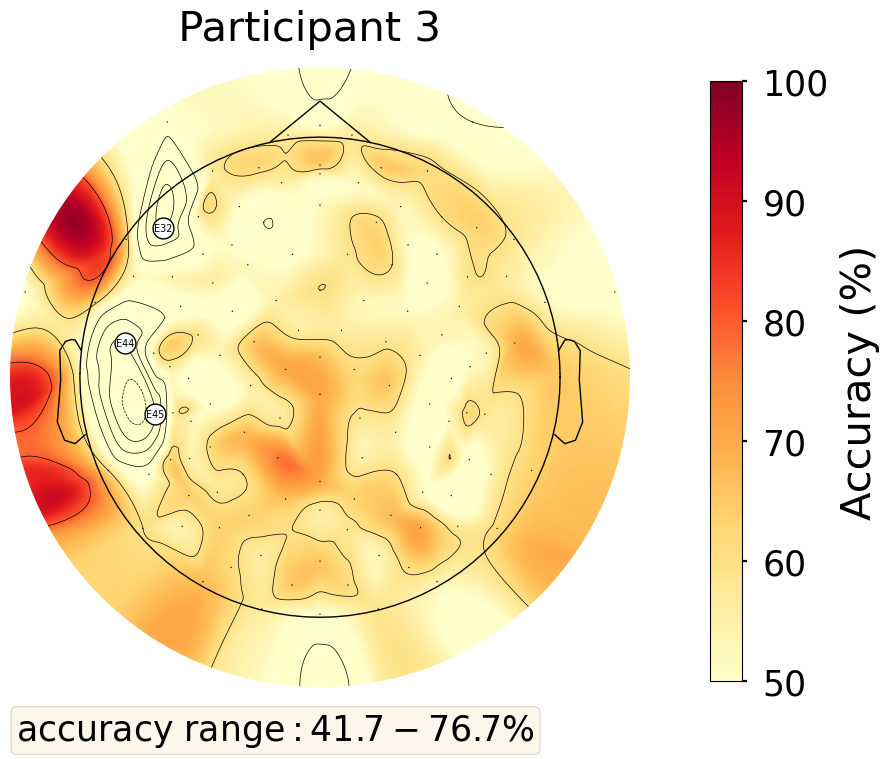

In [120]:
#testing formatting for topoplot uncorrected figures for all participants (50-100% accuracy)
for si, subject in enumerate(['EP03']):    #subject = sys.argv[1]

    # Files to save:
    fig_fname = (
        project_path
        + "/results_alias/ch1-by_channel/figures/w1000/{}_by_channel".format(subject)
    )

    obs_fname ='{}/{}_by_channel_test.npy'.format(data_path, subject)
    obs_ = np.load(obs_fname)
    obs_m = obs_.mean(axis=1).squeeze()

    #number of channels
    test_d1 = obs_.shape[0]
    bad_d1 = get_bad_channels(project_path,subject) #bad channels
    good_d1, bad_d1, bad_names = channel_indices(test_d1, bad_d1)

    #min_acc.append(np.min(obs_m[good_d1]))
    #max_acc.append(np.max(obs_m[good_d1]))
    
    #print(obs_.shape,fdr_ind.shape)
    pval_fname = '{}/sig/{}_by_channel-pval.npy'.format(data_path, subject)
    pvalues = np.load(pval_fname)

    tmp = np.empty(shape=pvalues[good_d1].shape,dtype=int)
    tmp[:]=si
    PVALUES = np.concatenate([PVALUES,pvalues[good_d1]])
    subj_inds = np.concatenate((subj_inds,tmp))

    RESULTS_[subject] = {   'obs': obs_,
                            'obs_m': obs_m,
                            'min_acc': min_acc[-1],
                            'max_acc': max_acc[-1],
                            'pvalues': pvalues,
                            'd1': test_d1,
                            'good_d1': good_d1,
                            'bad_d1': bad_d1,
                            'bad_names': bad_names,
                            'fig_fname': fig_fname,
                            }
    
    info['bads'] = bad_names
    ch_badmask = np.isin(info.ch_names,info['bads'],invert=False)
    print(RESULTS_[subject]['min_acc'],RESULTS_[subject]['max_acc'])
    #res_tmp[RESULTS_[subject]['obs_m']<0.55] = 0
    fig, cbar_ax, colbr = plot_acc_brain(
        obs_m,
        info,
        subject=subject,
        params=params,
        ch_badmask=ch_badmask,
        title="",
        show=True,
        all_subjects=False,
        vmin=RESULTS_[subject]['min_acc'],
        vmax=RESULTS_[subject]['max_acc'])
        #fname=(RESULTS_[subject]['fig_fname'] + "_YlOrRd.png"))

0.4166666666666667 0.7666666666666667


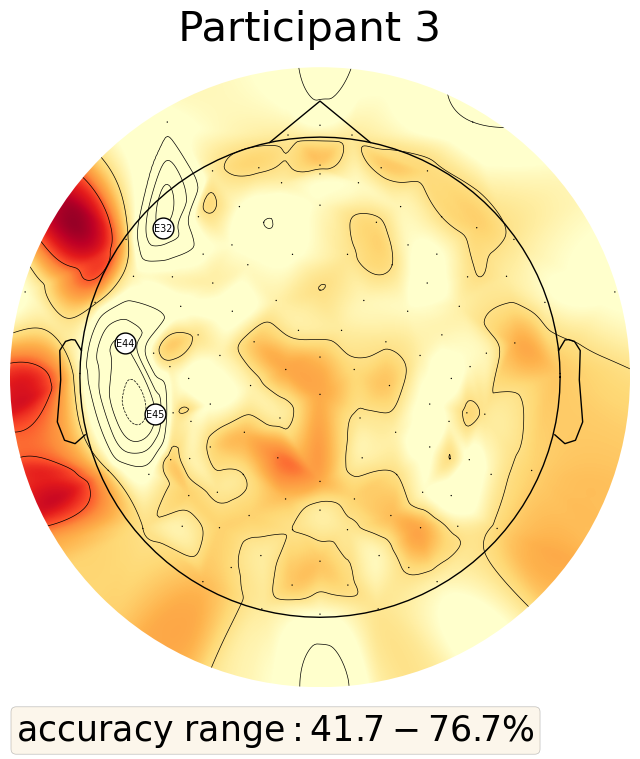

In [124]:
#testing formatting for topoplot uncorrected figures for all participants (50-100% accuracy)
for si, subject in enumerate(['EP03']):    #subject = sys.argv[1]

    # Files to save:
    fig_fname = (
        project_path
        + "/results_alias/ch1-by_channel/figures/w1000/{}_by_channel".format(subject)
    )

    obs_fname ='{}/{}_by_channel_test.npy'.format(data_path, subject)
    obs_ = np.load(obs_fname)
    obs_m = obs_.mean(axis=1).squeeze()

    #number of channels
    test_d1 = obs_.shape[0]
    bad_d1 = get_bad_channels(project_path,subject) #bad channels
    good_d1, bad_d1, bad_names = channel_indices(test_d1, bad_d1)

    #min_acc.append(np.min(obs_m[good_d1]))
    #max_acc.append(np.max(obs_m[good_d1]))
    
    #print(obs_.shape,fdr_ind.shape)
    pval_fname = '{}/sig/{}_by_channel-pval.npy'.format(data_path, subject)
    pvalues = np.load(pval_fname)

    tmp = np.empty(shape=pvalues[good_d1].shape,dtype=int)
    tmp[:]=si
    PVALUES = np.concatenate([PVALUES,pvalues[good_d1]])
    subj_inds = np.concatenate((subj_inds,tmp))

    RESULTS_[subject] = {   'obs': obs_,
                            'obs_m': obs_m,
                            'min_acc': min_acc[-1],
                            'max_acc': max_acc[-1],
                            'pvalues': pvalues,
                            'd1': test_d1,
                            'good_d1': good_d1,
                            'bad_d1': bad_d1,
                            'bad_names': bad_names,
                            'fig_fname': fig_fname,
                            }
    
    info['bads'] = bad_names
    ch_badmask = np.isin(info.ch_names,info['bads'],invert=False)
    print(RESULTS_[subject]['min_acc'],RESULTS_[subject]['max_acc'])
    #res_tmp[RESULTS_[subject]['obs_m']<0.55] = 0
    fig, cbar_ax, colbr = plot_acc_brain(
        obs_m,
        info,
        subject=subject,
        params=params,
        ch_badmask=ch_badmask,
        title="",
        show=True,
        all_subjects=False,
        vmin=RESULTS_[subject]['min_acc'],
        vmax=RESULTS_[subject]['max_acc'])
        #fname=(RESULTS_[subject]['fig_fname'] + "_YlOrRd.png"))

In [55]:
# Calculate the Benjamini-Hochberg FDR
reject, p_values_corrected, _, _ = multipletests(
    PVALUES.squeeze(), alpha=0.05, method="fdr_bh")
fdr_ind = reject.astype("int")

In [56]:
PVALUES.shape

(3555, 1)

In [57]:
p_values_corrected[subj_inds.squeeze()==0]

array([0.10316481, 0.18590961, 0.37809107, 0.13701917, 0.208493  ,
       0.20681126, 0.32789328, 0.14656097, 0.11262522, 0.44795274,
       0.47182838, 0.58401598, 0.35706012, 0.31024834, 0.08828781,
       0.35375213, 0.47657527, 0.35922698, 0.90426198, 0.45103644,
       0.2936114 , 0.13195645, 0.53136536, 0.53436147, 0.28563929,
       0.35305166, 0.62692237, 0.362971  , 0.74851158, 0.07754254,
       0.02925411, 0.38278309, 0.66213448, 0.24229509, 0.38204386,
       0.35459081, 0.37686705, 0.36922315, 0.31024834, 0.70557871,
       0.63877363, 0.13811189, 0.34225653, 0.44082666, 0.569873  ,
       0.48008767, 0.12700544, 0.35305166, 0.14530596, 0.07754254,
       0.28962348, 0.0325821 , 0.13312291, 0.63624578, 0.10316481,
       0.23964789, 0.19992801, 0.01092753, 0.02925411, 0.19212143,
       0.35459081, 0.12700544, 0.09981882, 0.07168061, 0.09206426,
       0.1527061 , 0.31108665, 0.14394861, 0.30665421, 0.31898358,
       0.08307482, 0.07168061, 0.22056546, 0.09620177, 0.35542

In [31]:
fdr_figfname = (
    project_path + "/results_alias/ch1-by_channel/figures/w1000/fdr_all_subjects/"
)
fill_path(fdr_figfname)

In [64]:
project_path

'/project_data/volume0/tpirnia/data/EEGWS/'

In [ ]:
/project_data/volume0/tpirnia/data/EEGWS/results_alias/ch1-by_channel/figures/w1000/fdr_all_subjects/

In [60]:
sum(reject)

859

In [83]:
subj_inds = subj_inds.squeeze()
for si, subject in enumerate(subject_list):
    good_d1 = RESULTS_[subject]["good_d1"]
    inds = subj_inds.squeeze() == si
    RESULTS_[subject]["fdr_pvalues"] = add_bad_ch_in(
        test_d1, RESULTS_[subject]["good_d1"], p_values_corrected[inds])
    RESULTS_[subject]["fdr_ind"] = add_bad_ch_in(
        test_d1, RESULTS_[subject]["good_d1"], fdr_ind[inds])
    notsig = np.isin(
        np.arange(test_d1),
        np.argwhere(RESULTS_[subject]["fdr_ind"].squeeze()),
        invert=True,)

    RESULTS_[subject]["obs_corr"] = mask_arr_by_ind(RESULTS_[subject]["obs_m"], notsig, 0)
    
    #figname = fdr_figfname + "{}_by_channel-fdr_YlOrRd.png".format(subject) 

    info['bads'] = RESULTS_[subject]['bad_names']
    ch_badmask = np.isin(info.ch_names,info['bads'],invert=False)
    
    fig, cbar_ax, colbr = plot_acc_brain(
        RESULTS_[subject]['obs_corr'],
        info,
        subject=subject,
        params=params,
        ch_badmask=ch_badmask,
        title="fdr-corrected",
        show=False,
        all_subjects=False,
        vmin=RESULTS_[subject]['min_acc'],
        vmax=RESULTS_[subject]['max_acc'])
        #fname=figname)

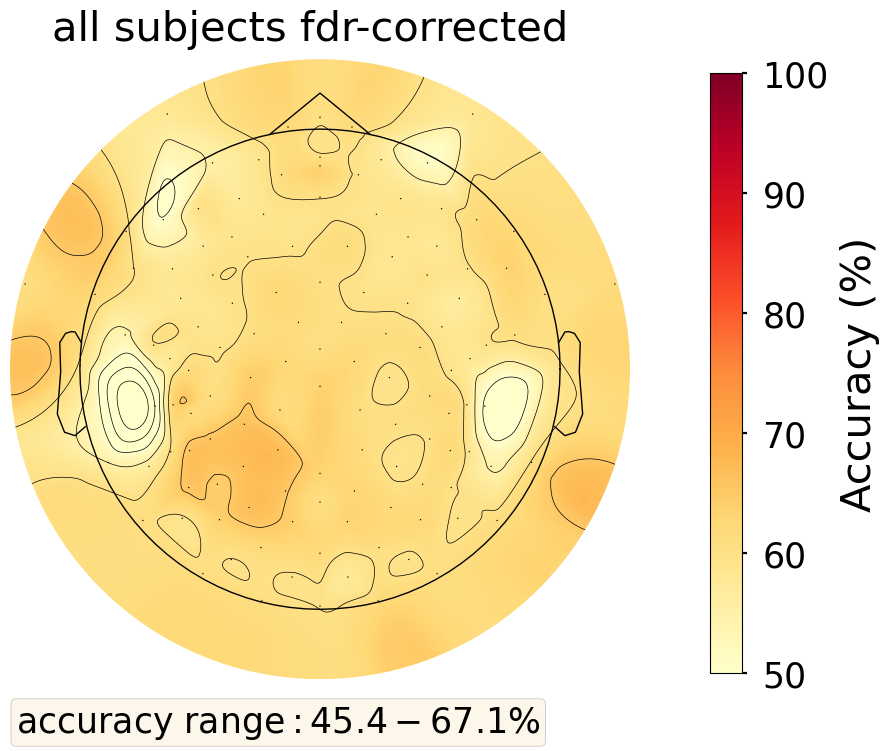

In [149]:
all_subj_corr = list((RESULTS_[subject]['obs_m']) for subject in subject_list)

all_subj_corr = np.vstack(all_subj_corr).mean(axis=0).squeeze()


fig, cbar_ax, colbr = plot_acc_brain(
        all_subj_corr,
        info,
        subject='all subjects',
        all_subjects = True,
        params=params,
        ch_badmask=[False],
        title="fdr-corrected",
        show=True,
        vmin=min(all_subj_corr),
        vmax=max(all_subj_corr))
#I didn't save this one.

_______

## TROUBLESHOOTING BELOW:

In [362]:
import os, sys
import numpy as np
import itertools, warnings

sys.path.append("/project_data/volume0/tpirnia/data/EEGWS/code")
from stats.fdr import fdr_correction
from data_handling.preprocessing import get_bad_channels


def fill_path(fname):
    if not os.path.exists(os.path.dirname(fname)):
        os.makedirs(os.path.dirname(fname), exist_ok=True)


def nulldist(nulls, yhat):
    """CALCULATE P-VALUE"""
    pv0 = sum(nulls >= yhat) + 1
    return pv0 / (len(nulls) + 1)


def channel_indices(n_channels, bad_channels):
    channels = np.arange(n_channels)
    good_ch = channels[np.isin(channels, bad_channels, invert=True)]
    # mask_ch = np.argwhere(good_ch).squeeze()
    bad_names = list("E" + str(bc + 1) for bc in bad_channels)
    return  good_ch, bad_channels, bad_names


subject_list = "EP03 EP05 EP06 EP07 EP09 EP10 EP11 EP12 EP13 EP14 EP15 EP16 EP17 EP18 EP19 EP20 EP21 EP22 EP23 EP25 EP26 EP27 EP28 EP29 EP30 EP31 EP32 EP33".split(
    " "
)
# subject = sys.argv[1]
w, s = 1000, 500
# w,s = map(int,sys.argv[2:])
project_path = "/project_data/volume0/tpirnia/data/EEGWS/"
data_path = "{}results_alias/ch1-by_channel/data/w{}".format(project_path, w)

min_acc, max_acc = [], []
RESULTS_ = {}

for subject in subject_list:    #subject = sys.argv[1]

    # Files to save:
    fig_fname = (
        project_path
        + "/results_alias/ch1-by_channel/figures/w1000/{}_by_channel".format(subject)
    )

    obs_fname ='{}/{}_by_channel_test.npy'.format(data_path, subject)
    obs_ = np.load(obs_fname)
    obs_m = obs_.mean(axis=1).squeeze()

    #number of channels
    test_d1 = obs_.shape[0]
    bad_d1 = get_bad_channels(project_path,subject) #bad channels
    good_d1, bad_d1, bad_names = channel_indices(test_d1, bad_d1)

    min_acc += [np.min(obs_m[good_d1])]
    max_acc += [np.max(obs_m[good_d1])]
    
    #print(obs_.shape,fdr_ind.shape)
    pval_fname = '{}/sig/{}_by_channel-pval.npy'.format(data_path, subject)
    pvalues = np.load(pval_fname)


    RESULTS_[subject] = {   'obs': obs_,
                            'obs_m': obs_m,
                            'min_acc': min_acc[-1],
                            'max_acc': max_acc[-1],
                            'pvalues': pvalues,
                            'd1': test_d1,
                            'good_d1': good_d1,
                            'bad_d1': bad_d1,
                            'bad_names': bad_names,
                            'fig_fname': fig_fname,
                            }
    info['bads'] = RESULTS_[subject]['bad_names']

    ch_badmask = np.isin(info.ch_names,info['bads'],invert=False)

    fig, cbar_ax, colbr = plot_acc_brain(
        obs_m,
        info,
        subject=subject,
        params=params,
        ch_badmask=ch_badmask,
        title="uncorrected results",
        show=True,
        all_subjects=False,
        vmin=min_acc[-1],
        vmax=max_acc[-1])
min_acc, max_acc = map(np.array,[min_acc,max_acc])

In [44]:
# plot figures per subject

In [123]:
import matplotlib.pyplot as plt
import mne

from mpl_toolkits import axes_grid1
from matplotlib import colors
import matplotlib as mpl


import seaborn as sns

params = {'lines.markersize':6,
          'axes.labelsize': 21,
          'axes.titlesize':20,
          'axes.labelpad':8,
          'xtick.labelsize' :18,
          'ytick.labelsize' :18,
          'xtick.major.pad':5, 
          'ytick.major.pad':5, 
          'legend.title_fontsize':18,
          'figure.figsize':(8,10),
          'figure.subplot.hspace': .9,
          'figure.subplot.wspace': .4,
          'image.origin': 'lower',
          'figure.titlesize': 25,
          'figure.autolayout': False,
          'scatter.marker':'o',
          'savefig.dpi': 450,
          'savefig.bbox': 'tight',
          'savefig.transparent': True,
         }

In [369]:
def plot_acc_brain(
    arr,
    info,
    subject,
    params,
    ch_badmask=None,
    title="",
    fname="",
    show=True,
    all_subjects=False,
    vmax=100,
    vmin=50,
):
    if arr.ndim > 1:
        arr = arr.squeeze()
    mask_params = dict(
        marker="o", markerfacecolor="w", markeredgecolor="k", linewidth=0, markersize=15
    )
    with mpl.rc_context(params):
        # plt.style.use('seaborn-darkgrid')
        plt.style.use("seaborn-poster")
        fig, ax = plt.subplots(figsize=(8, 8))
        if any(ch_badmask):
            im, cm = mne.viz.plot_topomap(
                arr * 100,
                pos=info,
                axes=ax,
                show=False,
                show_names=True,
                names=info.ch_names,
                mask=ch_badmask,
                cmap="YlOrRd",
                mask_params=mask_params,
                vmin=55,
                vmax=100,
                res=300,
                ch_type="eeg",
                image_interp="none")
        else:
            im, cm = mne.viz.plot_topomap(
                arr * 100,
                pos=info,
                axes=ax,
                show=False,
                show_names=False,
                names=info.ch_names,
                vmax=vmax,
                vmin=vmin,
                res=300,
                ch_type="eeg",
                cmap="YlOrRd",
                image_interp="none")  
            textstr = r"accuracy range$:%.1f-%.1f$%%" % (arr.min() * 100, 
                                                         arr.max() * 100)
        textstr = r"accuracy range$:%.1f-%.1f$%%" % (vmin * 100, 
                                             vmax * 100)
        if all_subjects:
            fig.suptitle("{}: {}".format(subject, title))

        else:
            fig.suptitle(" Subject {}: {}".format(subject, title))

        ax_x_start = 1.0
        ax_x_width = 0.04
        ax_y_start = 0.15
        ax_y_height = 0.75
        cbar_ax = fig.add_axes([ax_x_start, ax_y_start, ax_x_width, ax_y_height])
        clb = fig.colorbar(im, cax=cbar_ax, label="accuracy (%)")
        clb.mappable.set_clim(55,100)
        clb.set_ticks([ 55.,  60.,  65.,  70.,  75.,  80.,  85.,  90.,  95., 100.])
        cbar_ax.axes._get_axis_list()[1].set_label_text("accuracy (%)", size=20)

        cbar_ax.axes._get_axis_list()[1].set_label_position("left")

        props = dict(boxstyle="round", facecolor="wheat", alpha=0.25)

        # place a text box in upper left in axes coords
        ax.text(
            0.01,
            -0.04,
            textstr,
            transform=ax.transAxes,
            fontsize=20,
            verticalalignment="top",
            bbox=props,
        )
        if fname:
            plt.savefig(fname, dpi=450, transparent=True, bbox_inches="tight")
        if show:
            plt.show()
        else:
            plt.close()
        return fig, cbar_ax, clb


In [155]:
sfreq = float(1000)
decim = 2

montage = mne.channels.make_standard_montage("GSN-HydroCel-129")

EP03


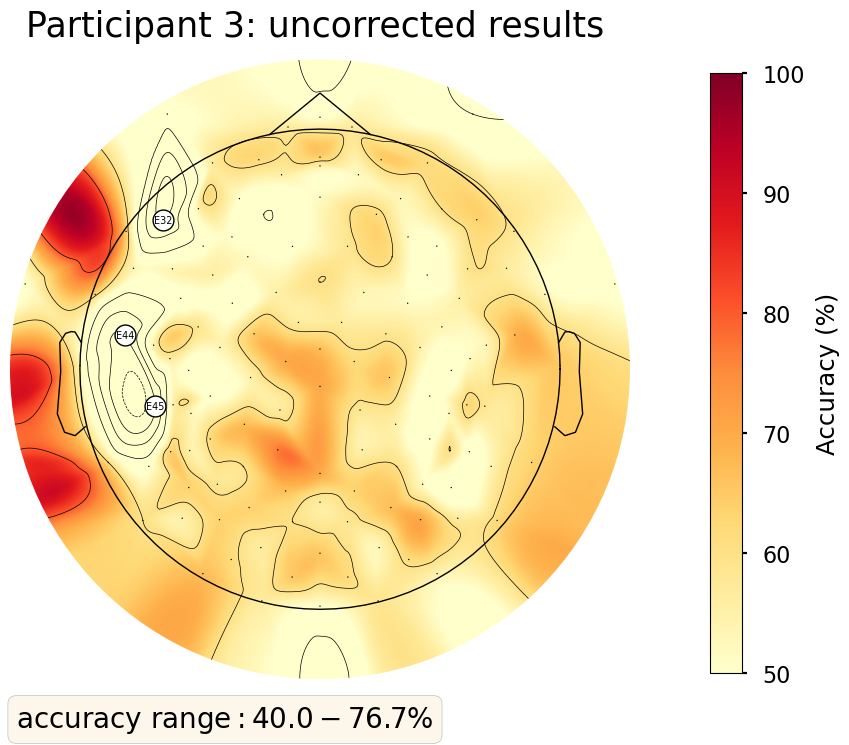

In [25]:
subject='EP03'
print(subject)
info = mne.create_info(montage.ch_names, sfreq=sfreq, ch_types="eeg",verbose=0)
info.set_montage(montage, verbose=0)
info['bads'] = RESULTS_[subject]['bad_names']

ch_badmask = np.isin(info.ch_names,info['bads'],invert=False)
res_tmp = RESULTS_[subject]['obs_m'].copy()
fig, cbar_ax, colbr = plot_acc_brain(
    res_tmp,
    info,
    subject=subject,
    params=params,
    ch_badmask=ch_badmask,
    title="uncorrected results",
    show=True,
    all_subjects=False,
    vmin=RESULTS_[subject]['min_acc'],
    vmax=RESULTS_[subject]['max_acc'])

In [167]:
for subject in subject_list: 
    info = mne.create_info(montage.ch_names, sfreq=sfreq, ch_types="eeg",verbose=0)
    info.set_montage(montage, verbose=0)
    info['bads'] = RESULTS_[subject]['bad_names']
    ch_badmask = np.isin(info.ch_names,info['bads'],invert=False)
    res_tmp = RESULTS_[subject]['obs_m'].copy()
    #res_tmp[RESULTS_[subject]['obs_m']<0.55] = 0
    fig, cbar_ax, colbr = plot_acc_brain(
        res_tmp,
        info,
        subject=subject,
        params=params,
        ch_badmask=ch_badmask,
        title="uncorrected results",
        show=False,
        all_subjects=False,
        vmin=RESULTS_[subject]['min_acc'],
        vmax=RESULTS_[subject]['max_acc'],
        fname=(RESULTS_[subject]['fig_fname'] + "_YlOrRd.png"))
    del(res_tmp)

    RESULTS_[subject] = {   'obs': obs_m,
                            'obs_m': obs_m,
                            'min_acc': min_acc[-1],
                            'max_acc': max_acc[-1],
                            'pvalues': pvalues,
                            'd1': test_d1,
                            'good_d1': good_d1,
                            'bad_d1': bad_d1,
                            'bad_names': bad_names,
                            'fig_fname': fig_fname,
                            }

In [373]:
PVALUES = np.empty((0,1))
subj_inds = np.empty((0,1),dtype=np.int)
for si, subject in enumerate(subject_list):
    good_d1 = RESULTS_[subject]['good_d1']
    pvalues = RESULTS_[subject]['pvalues'].copy()
    tmp = np.empty(shape=pvalues[good_d1].shape,dtype=np.int)
    tmp[:]=si
    PVALUES = np.concatenate([PVALUES,pvalues[good_d1]])
    subj_inds = np.concatenate((subj_inds,tmp))
    

In [379]:
min(PVALUES)

array([0.000999])

In [374]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    testd1,testd2= PVALUES.shape
    fdr_ind, fdr_pvalues = np.zeros((testd1, testd2), dtype=np.int), np.zeros((testd1, testd2))
    fdr_ind, fdr_pvalues = fdr_correction(PVALUES, alpha=0.05, method="by")


In [331]:
import os, sys
import numpy as np
import itertools, warnings

sys.path.append("/project_data/volume0/tpirnia/data/EEGWS/code")
from stats.fdr import fdr_correction
from data_handling.preprocessing import get_bad_channels


def fill_path(fname):
    if not os.path.exists(os.path.dirname(fname)):
        os.makedirs(os.path.dirname(fname), exist_ok=True)


def nulldist(nulls, yhat):
    """CALCULATE P-VALUE"""
    pv0 = sum(nulls >= yhat) + 1
    return pv0 / (len(nulls) + 1)


def channel_indices(n_channels, bad_channels):
    channels = np.arange(n_channels)
    good_ch = channels[np.isin(channels, bad_channels, invert=True)]
    # mask_ch = np.argwhere(good_ch).squeeze()
    bad_names = list("E" + str(bc + 1) for bc in bad_channels)
    return  good_ch, bad_channels, bad_names


subject_list = "EP03 EP05 EP06 EP07 EP09 EP10 EP11 EP12 EP13 EP14 EP15 EP16 EP17 EP18 EP19 EP20 EP21 EP22 EP23 EP25 EP26 EP27 EP28 EP29 EP30 EP31 EP32 EP33".split(
    " "
)
# subject = sys.argv[1]
w, s = 1000, 500
# w,s = map(int,sys.argv[2:])
project_path = "/project_data/volume0/tpirnia/data/EEGWS/"
data_path = "{}results_alias/ch1-by_channel/data/w{}".format(project_path, w)

min_acc, max_acc = [], []
RESULTS_ = {}

for subject in subject_list:    #subject = sys.argv[1]

    # Files to save:
    fig_fname = (
        project_path
        + "/results_alias/ch1-by_channel/figures/w1000/{}_by_channel".format(subject)
    )

    obs_fname ='{}/{}_by_channel_test.npy'.format(data_path, subject)
    obs_ = np.load(obs_fname)
    obs_m = obs_.mean(axis=1)#.squeeze()
    
    nulls_fname = '{}/null/{}_by_channel_test.npy'.format(data_path, subject)
    nulls_ = np.load(nulls_fname)
    nulls_ = nulls_.swapaxes(0,1)
    nulls_ = np.mean(nulls_, axis=2).squeeze()[:,:,np.newaxis] 
    

    test_d1 = obs_.shape[0]
    bad_d1 = get_bad_channels(project_path,subject) #bad channels
    good_d1, bad_d1, bad_names = channel_indices(test_d1, bad_d1)

    testd1,testd2 = nulls_.shape[0], nulls_.shape[-1]
    pvalues=np.zeros((testd1, testd2))
    for j,k in itertools.product(good_d1,np.arange(testd2)):
        pvalues[j,k] = nulldist(nulls_[j,:,k].squeeze(),obs_m[j,k])
        pvalues[bad_d1] = np.nan
        

    min_acc += [np.min(obs_m[good_d1])]
    max_acc += [np.max(obs_m[good_d1])]
    
    #print(obs_.shape,fdr_ind.shape)
    pval_fname = '{}/sig/all_subjects/{}_by_channel-pval.npy'.format(data_path, subject)
    fill_path(pval_fname)
    np.save(pval_fname,pvalues)

    RESULTS_[subject] = {   'obs': obs_,
                            'obs_m': obs_.mean(axis=1).squeeze(),
                            'min_acc': min_acc[-1],
                            'max_acc': max_acc[-1],
                            'pvalues': pvalues,
                            'd1': test_d1,
                            'good_d1': good_d1,
                            'bad_d1': bad_d1,
                            'bad_names': bad_names,
                            'fig_fname': fig_fname,
                            }
min_acc, max_acc = map(np.array,[min_acc,max_acc])

In [356]:
def add_bad_ch_in(n_channels, good_ch, arr):
    """ for full trial only, needs a second dimension for time otherwise.
    """
    tmp_ = np.zeros(shape=(n_channels,))
    tmp_[good_ch] = arr.copy()
    return tmp_

In [473]:
~reject

array([ True,  True,  True, ..., False, False,  True])

In [477]:
reject.astype('int')

array([0, 0, 0, ..., 1, 1, 0])

In [ ]:
statsmodels.stats.multitest.fdrcorrection(pvals, alpha=0.05, method='indep',

In [458]:
from statsmodels.stats.multitest import multipletests

# Calculate the Benjamini-Hochberg FDR
reject, p_values_corrected, _, _ = multipletests(PVALUES.squeeze(), alpha=0.05,method='fdr_bh')

# Print the number of rejected hypotheses and the corrected p-values
print("Number of rejected hypotheses:", np.sum(reject))
print("Corrected p-values:", p_values_corrected)

Number of rejected hypotheses: 859
Corrected p-values: [0.10316481 0.18590961 0.37809107 ... 0.02545841 0.03592506 0.37293504]


In [485]:
subj_inds.shape

(3555, 1)

In [486]:
fdr_ind = reject.astype('int')
subj_inds = subj_inds.squeeze()
for si, subject in enumerate(subject_list):
    good_d1 = RESULTS_[subject]['good_d1']
    RESULTS_[subject]['fdr_pvalues'] = add_bad_ch_in(test_d1, RESULTS_[subject]['good_d1'],p_values_corrected[subj_inds==si])
    RESULTS_[subject]['fdr_ind'] = add_bad_ch_in(test_d1, RESULTS_[subject]['good_d1'],fdr_ind[subj_inds==si])
    notsig = np.isin(np.arange(test_d1), np.argwhere(RESULTS_[subject]['fdr_ind'].squeeze()),invert=True)

    RESULTS_[subject]['obs_corr'] = RESULTS_[subject]['obs_m'].copy()
    RESULTS_[subject]['obs_corr'][notsig]  = 0
    

In [491]:
RESULTS_[subject]['fig_fname'] 

'/project_data/volume0/tpirnia/data/EEGWS//results_alias/ch1-by_channel/figures/w1000/EP11_by_channel'

In [498]:
fdr_figfname = (
        project_path + "/results_alias/ch1-by_channel/figures/w1000/fdr_all_subjects/"
    )
fill_path(fdr_figfname)

In [502]:
def mask_arr_by_ind(arr, inds, mask_value):
    arr_tmp = arr.copy()
    arr_tmp[inds] = mask_value
    return arr_tmp

In [503]:
tmptmp = mask_arr_by_ind(RESULTS_[subject]["obs_m"], notsig, 0)

True

In [500]:
for subject in subject_list: 
    figname = fdr_figfname + "{}_by_channel-fdr_YlOrRd.png".format(subject) 
    info = mne.create_info(montage.ch_names, sfreq=sfreq, ch_types="eeg",verbose=0)
    info.set_montage(montage, verbose=0)
    info['bads'] = RESULTS_[subject]['bad_names']
    ch_badmask = np.isin(info.ch_names,info['bads'],invert=False)
    fig, cbar_ax, colbr = plot_acc_brain(
        RESULTS_[subject]['obs_corr'],
        info,
        subject=subject,
        params=params,
        ch_badmask=ch_badmask,
        title="uncorrected results",
        show=False,
        all_subjects=False,
        vmin=RESULTS_[subject]['min_acc'],
        vmax=RESULTS_[subject]['max_acc'],
        fname=figname)

______

In [302]:
tmp_[good_d1]


array([1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 0.41702726, 1.        ,
       1.        , 1.        , 1.        , 1.        , 0.49979882,
       0.66085002, 0.31446879, 0.45872568, 1.        , 1.        ,
       1.        , 0.77282444, 0.62745385, 0.57345849, 1.        ,
       0.49979882, 1.        , 0.7438425 , 1.        , 1.        ,
       1.        , 0.2852063 , 1.        , 0.18286757, 1.        ,
       1.        , 1.        , 0.2852063 , 0.22284937, 0.18286757,
       1.        , 1.        , 0.45872568, 0.80588142, 0.41702726,
       1.        , 0.2852063 , 0.51704759, 1.        , 1.        ,
       1.        , 1.        , 1.        , 1.        , 0.53708056,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       0.14560884, 0.64241886, 1.        , 0.0956538 , 0.77282444,
       0.25607485, 0.14560884, 1.        , 1.        , 1.        ,
       0.14560884, 0.51704759, 1.        , 1.        , 1.     

In [168]:
subject=subject_list[0]
good_d1 = RESULTS_[subject]['good_d1']
pvalues = RESULTS_[subject]['pvalues'].copy()

In [170]:
subject_2=subject_list[1]
good_d1_2 = RESULTS_[subject_2]['good_d1']
pvalues_2 = RESULTS_[subject_2]['pvalues'].copy()

In [179]:
tmp = np.array((50,1))

In [208]:
tmp = np.empty(shape=pvalues_2[good_d1_2].shape,dtype=np.int)

In [245]:
fdr_tmp = add_bad_ch_in(129, RESULTS_[subject]['good_d1'],fdr_pvalues[subj_inds==si])

In [251]:
tmp_=np.zeros(shape=(129,))

In [254]:
tmp_[RESULTS_[subject]['good_d1']] = fdr_pvalues[subj_inds==si]

In [260]:
any(fdr_ind)

False

In [258]:
[subj_inds==7]

array([1.        , 1.        , 1.        , 1.        , 1.        ,
       0.45872568, 0.0956538 , 1.        , 1.        , 0.99653267,
       0.53708056, 0.22284937, 1.        , 1.        , 0.72719267,
       0.31446879, 1.        , 0.57345849, 0.64241886, 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       0.91762919, 1.        , 1.        , 0.51704759, 0.7438425 ,
       0.22284937, 1.        , 1.        , 1.        , 1.        ,
       0.82868395, 1.        , 1.        , 1.        , 0.22284937,
       0.53708056, 1.        , 1.        , 1.        , 1.        ,
       1.        , 0.37304984, 1.        , 1.        , 1.        ,
       0.7131369 , 1.        , 1.        , 0.31446879, 1.        ,
       0.51704759, 1.        , 1.        , 0.93462737, 0.91762919,
       0.34445968, 1.        , 0.57345849, 1.        , 1.        ,
       0.90304972, 0.60955856, 1.        , 1.        , 1.        ,
       1.        , 0.62745385, 0.60955856, 1.        , 1.     

In [255]:
tmp_

array([1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 0.41702726, 1.        ,
       1.        , 1.        , 1.        , 1.        , 0.49979882,
       0.66085002, 0.31446879, 0.45872568, 1.        , 1.        ,
       1.        , 0.77282444, 0.62745385, 0.57345849, 1.        ,
       0.49979882, 1.        , 0.7438425 , 1.        , 1.        ,
       1.        , 0.2852063 , 1.        , 0.18286757, 1.        ,
       1.        , 1.        , 0.2852063 , 0.22284937, 0.18286757,
       1.        , 1.        , 0.45872568, 0.80588142, 0.        ,
       0.41702726, 1.        , 0.2852063 , 0.51704759, 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       0.53708056, 0.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 0.14560884, 0.64241886, 1.        ,
       0.0956538 , 0.77282444, 0.25607485, 0.14560884, 1.        ,
       1.        , 1.        , 0.14560884, 0.51704759, 1.     

In [334]:
del(tmp, tmp_, fdr_tmp, bad_d1,bad_names,good_d1_2, good_d1)

In [297]:
tmp = np.unique(subj_inds[np.argwhere(PVALUES<.000)[:,0]])

In [303]:
nulldist(tmp_[good_d1],tmp_[good_d1])

1.0

In [308]:
tmp_[good_d1].squeeze()

array([1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 0.41702726, 1.        ,
       1.        , 1.        , 1.        , 1.        , 0.49979882,
       0.66085002, 0.31446879, 0.45872568, 1.        , 1.        ,
       1.        , 0.77282444, 0.62745385, 0.57345849, 1.        ,
       0.49979882, 1.        , 0.7438425 , 1.        , 1.        ,
       1.        , 0.2852063 , 1.        , 0.18286757, 1.        ,
       1.        , 1.        , 0.2852063 , 0.22284937, 0.18286757,
       1.        , 1.        , 0.45872568, 0.80588142, 0.41702726,
       1.        , 0.2852063 , 0.51704759, 1.        , 1.        ,
       1.        , 1.        , 1.        , 1.        , 0.53708056,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       0.14560884, 0.64241886, 1.        , 0.0956538 , 0.77282444,
       0.25607485, 0.14560884, 1.        , 1.        , 1.        ,
       0.14560884, 0.51704759, 1.        , 1.        , 1.     

In [307]:
tmp_[good_d1][k]

1.0

In [309]:
nulldist(tmp_[good_d1].squeeze(),tmp_[good_d1][k])

0.696

In [313]:
pvalues1#[j,k]

array([[0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [  nan],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [  nan],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [0.696],
       [

In [298]:
sig_ = [subject_list[i] for i in tmp]

In [299]:
sig_

[]

In [262]:
PVALUES.shape

(3555, 1)

In [232]:
fdr_ind.shape

(3555, 1)

In [236]:
fdr_pvalues.shape

(3555, 1)

In [235]:
fdr_ind[subj_inds==0].shape

(126,)